In [1]:
import pandas as pd
import numpy as np
import random

import torch
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
from torch import optim

from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [21]:
train_data = pd.read_csv("../data/rck_growth_train.csv")
test_data = pd.read_csv("../data/rck_growth_test.csv")

In [22]:
train_data.head()

,alpha,delta,rho,theta,n,g,k0_initial,c0_initial,t_grid_0,t_grid_1,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,0.341578,0.051447,0.031636,2.544645,0.024043,0.013434,5.072306,1.244839,0.0,0.20202,...,1.177143,1.175453,1.173739,1.172001,1.170239,1.168454,1.166644,1.164811,1.162953,1.161072
1,0.335347,0.045782,0.029641,1.981100,0.013845,0.016189,6.590784,1.307296,0.0,0.20202,...,1.066791,1.062920,1.059030,1.055119,1.051190,1.047241,1.043275,1.039290,1.035289,1.031271
2,0.300506,0.038040,0.031949,2.537843,0.023039,0.014485,4.763839,1.099017,0.0,0.20202,...,0.923553,0.920487,0.917406,0.914311,0.911202,0.908079,0.904942,0.901793,0.898631,0.895456
3,0.359424,0.060158,0.037301,2.363039,0.018581,0.015518,5.159358,1.157175,0.0,0.20202,...,0.906613,0.902429,0.898230,0.894019,0.889795,0.885559,0.881312,0.877054,0.872786,0.868508
4,0.308603,0.032851,0.014219,2.378382,0.020887,0.014675,7.177988,1.513421,0.0,0.20202,...,1.766734,1.781256,1.796703,1.813310,1.831537,1.852068,1.875817,1.903920,1.937741,1.978868


In [23]:
# Parameters
print(*train_data.iloc[:, :8].columns, sep='\n')

alpha
delta
rho
theta
n
g
k0_initial
c0_initial


In [24]:
# Grid
print(len(train_data.filter(like='t_grid').columns))
train_data.filter(like='t_grid')

100


,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,t_grid_7,t_grid_8,t_grid_9,...,t_grid_90,t_grid_91,t_grid_92,t_grid_93,t_grid_94,t_grid_95,t_grid_96,t_grid_97,t_grid_98,t_grid_99
0,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
2,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
3,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
4,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
396,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
397,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
398,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0


In [25]:
# k values (grid as arg)
print(len(train_data.filter(like='k_t').columns))
train_data.filter(like='k_t')

100


,k_t0,k_t1,k_t2,k_t3,k_t4,k_t5,k_t6,k_t7,k_t8,k_t9,...,k_t90,k_t91,k_t92,k_t93,k_t94,k_t95,k_t96,k_t97,k_t98,k_t99
0,5.072306,5.081514,5.090778,5.100099,5.109482,5.118929,5.128443,5.138027,5.147684,5.157417,...,6.523511,6.552083,6.581056,6.610432,6.640217,6.670415,6.701029,6.732065,6.763525,6.795415
1,6.590784,6.606136,6.621869,6.637989,6.654500,6.671408,6.688716,6.706430,6.724556,6.743097,...,10.095661,10.164621,10.234299,10.304694,10.375804,10.447629,10.520166,10.593414,10.667372,10.742038
2,4.763839,4.792160,4.820735,4.849572,4.878675,4.908052,4.937707,4.967648,4.997880,5.028410,...,8.895383,8.962855,9.030802,9.099219,9.168104,9.237455,9.307267,9.377539,9.448266,9.519445
3,5.159358,5.191880,5.224786,5.258085,5.291785,5.325896,5.360426,5.395385,5.430780,5.466621,...,10.391830,10.479710,10.568180,10.657232,10.746860,10.837056,10.927815,11.019128,11.110988,11.203387
4,7.177988,7.144201,7.110411,7.076609,7.042787,7.008935,6.975046,6.941110,6.907117,6.873060,...,2.297884,2.167244,2.031025,1.888602,1.739019,1.580991,1.412901,1.232802,1.038417,0.827140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,9.870126,9.861387,9.852888,9.844626,9.836601,9.828809,9.821250,9.813923,9.806824,9.799954,...,9.937797,9.948133,9.958691,9.969473,9.980479,9.991710,10.003167,10.014850,10.026761,10.038901
396,5.037843,5.091658,5.146042,5.201003,5.256548,5.312682,5.369412,5.426745,5.484685,5.543239,...,12.253382,12.353840,12.454478,12.555286,12.656254,12.757372,12.858629,12.960015,13.061521,13.163136
397,5.630703,5.631568,5.632351,5.633052,5.633671,5.634207,5.634662,5.635035,5.635326,5.635536,...,5.307144,5.296556,5.285716,5.274619,5.263260,5.251635,5.239738,5.227565,5.215109,5.202367
398,6.546160,6.528703,6.511028,6.493129,6.475000,6.456634,6.438026,6.419168,6.400052,6.380673,...,2.394184,2.261201,2.121845,1.975623,1.821392,1.658323,1.485225,1.300265,1.100977,0.884257


In [26]:
# c values (grid as arg)
print(len(train_data.filter(like='c_t').columns))
train_data.filter(like='c_t')

100


,c_t0,c_t1,c_t2,c_t3,c_t4,c_t5,c_t6,c_t7,c_t8,c_t9,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,1.244839,1.244832,1.244811,1.244776,1.244727,1.244664,1.244587,1.244496,1.244391,1.244271,...,1.177143,1.175453,1.173739,1.172001,1.170239,1.168454,1.166644,1.164811,1.162953,1.161072
1,1.307296,1.305723,1.304132,1.302522,1.300894,1.299247,1.297580,1.295894,1.294187,1.292461,...,1.066791,1.062920,1.059030,1.055119,1.051190,1.047241,1.043275,1.039290,1.035289,1.031271
2,1.099017,1.098482,1.097910,1.097303,1.096659,1.095979,1.095264,1.094513,1.093726,1.092904,...,0.923553,0.920487,0.917406,0.914311,0.911202,0.908079,0.904942,0.901793,0.898631,0.895456
3,1.157175,1.156310,1.155397,1.154434,1.153422,1.152361,1.151251,1.150092,1.148884,1.147628,...,0.906613,0.902429,0.898230,0.894019,0.889795,0.885559,0.881312,0.877054,0.872786,0.868508
4,1.513421,1.513054,1.512720,1.512420,1.512154,1.511922,1.511725,1.511562,1.511434,1.511342,...,1.766734,1.781256,1.796703,1.813310,1.831537,1.852068,1.875817,1.903920,1.937741,1.978868
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,1.493321,1.492153,1.490992,1.489839,1.488694,1.487556,1.486426,1.485303,1.484186,1.483076,...,1.398953,1.397801,1.396642,1.395475,1.394301,1.393119,1.391929,1.390731,1.389524,1.388310
396,1.017750,1.016384,1.014946,1.013439,1.011861,1.010215,1.008501,1.006720,1.004872,1.002959,...,0.713373,0.709113,0.704855,0.700601,0.696350,0.692104,0.687863,0.683627,0.679397,0.675174
397,1.204137,1.204550,1.204961,1.205371,1.205779,1.206187,1.206594,1.207000,1.207405,1.207810,...,1.258007,1.259180,1.260380,1.261607,1.262862,1.264146,1.265459,1.266803,1.268177,1.269584
398,1.567616,1.568066,1.568535,1.569025,1.569534,1.570064,1.570615,1.571187,1.571781,1.572397,...,1.833971,1.847149,1.861393,1.876831,1.893893,1.912740,1.933808,1.957990,1.986626,2.021513


# Prosty Model

In [30]:
def prepare_data(df):
    params = df.iloc[:, :8].values
    t_grid = df.filter(like='t_grid').values
    yk_values = df.filter(like='k_t').values
    yc_values = df.filter(like='c_t').values
    return params, t_grid, yk_values, yc_values

# Przetwarzanie
params_train, t_train, yk_train, yc_train = prepare_data(train_data)
params_test, t_test, yk_test, yc_test = prepare_data(test_data)

scaler_params = StandardScaler()
params_train = scaler_params.fit_transform(params_train)
params_test = scaler_params.transform(params_test)

In [57]:
class DeepONetDataset(Dataset):
    def __init__(self, branch_inputs, trunk_inputs, k_targets, c_targets):
        self.branch_inputs = torch.FloatTensor(branch_inputs)
        self.trunk_inputs = torch.FloatTensor(trunk_inputs)
        self.targets = torch.FloatTensor(
            np.stack([k_targets, c_targets], axis=-1)
        )

    def __len__(self):
        return len(self.branch_inputs)

    def __getitem__(self, idx):
        return (
            self.branch_inputs[idx],  # [p]
            self.trunk_inputs[idx],   # [T]
            self.targets[idx]         # [T, 2]
        )

train_dataset = DeepONetDataset(params_train, t_train, yk_train, yc_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

test_dataset = DeepONetDataset(params_test, t_test, yk_test, yc_test)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [59]:
class DeepONet(nn.Module):
    def __init__(self, p=64):
        super().__init__()

        # Branch net
        self.branch = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, p)
        )

        # Trunk net
        self.trunk = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, p)
        )

        # osobny head dla k i c
        # self.head = nn.Linear(p, out_dim)
        self.head_k = nn.Linear(p, 1)
        self.head_c = nn.Linear(p, 1)

        self.bias = nn.Parameter(torch.zeros(2))

    # def forward(self, x_branch, x_trunk):
    #     B = self.branch(x_branch)
    #     x_trunk = x_trunk.unsqueeze(-1) if x_trunk.dim() == 2 else x_trunk   # FORCE SAFE SHAPE
    #     batch_size, num_points = x_trunk.shape[:2]
    #     t_flat = x_trunk.reshape(-1, 1)
    #     T_flat = self.trunk(t_flat)
    #     T = T_flat.view(batch_size, num_points, -1)
    #     B = B.unsqueeze(1)
    #     out = torch.sum(B * T, dim=-1)
    #     out = out.unsqueeze(-1)
    #     return out
    def forward(self, x_branch, x_trunk):
        B = self.branch(x_branch)
        x_trunk = x_trunk.unsqueeze(-1) if x_trunk.dim() == 2 else x_trunk
        batch_size, num_points = x_trunk.shape[:2]
        t_flat = x_trunk.reshape(-1, 1)
        T_flat = self.trunk(t_flat)
        T = T_flat.view(batch_size, num_points, -1)
        B = B.unsqueeze(1)

        # DeepONet core
        z = torch.sum(B * T, dim=-1)   # [B, T]
        z = z.unsqueeze(-1)            # [B, T, 1]
        k = self.head_k(z)             # [B, T, 1]
        c = self.head_c(z)             # [B, T, 1]
        out = torch.cat([k, c], dim=-1)  # [B, T, 2]

        return out

In [62]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DeepONet(p=128).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

epochs = 20
train_losses = []
val_losses = []

for epoch in range(epochs):
    # TRAIN
    model.train()
    total_train_loss = 0.0

    for branch, trunk, y in train_loader:
        branch = branch.to(device)
        trunk = trunk.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        print(branch.shape, trunk.shape)
        output = model(branch, trunk)  # [B, T, 2]
        loss = criterion(output, y)
        print(output.shape, y.shape)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # VALIDATION
    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for v_branch, v_trunk, v_y in test_loader:

            v_branch = v_branch.to(device)
            v_trunk = v_trunk.to(device)
            v_y = v_y.to(device)

            val_output = model(v_branch, v_trunk)

            v_loss = criterion(val_output, v_y)

            total_val_loss += v_loss.item()

    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f}"
    )

torch.Size([32, 8]) torch.Size([32, 100])


RuntimeError: mat1 and mat2 shapes cannot be multiplied (3200x1 and 128x1)

In [41]:
print(pred.shape)

torch.Size([32, 100, 1])


IndexError: index 1 is out of bounds for dimension 2 with size 1

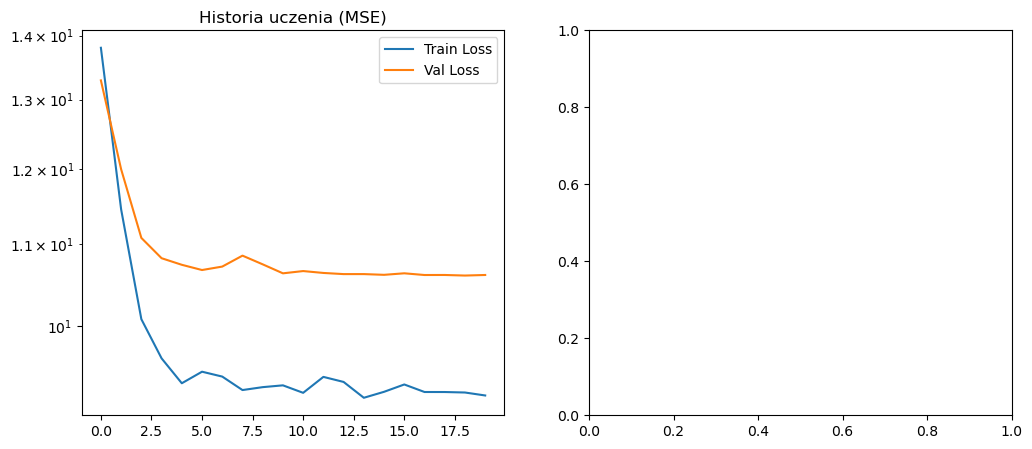

In [40]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.yscale('log')
plt.title('Historia uczenia (MSE)')
plt.legend()

plt.subplot(1, 2, 2)
with torch.no_grad():
    sample_b, sample_t, sample_y = next(iter(test_loader))

    sample_b = sample_b.to(device)
    sample_t = sample_t.to(device)
    sample_y = sample_y.to(device)

    pred = model(sample_b, sample_t)  # [B, T, 2]

    # wybieramy pierwszy przykład z batcha
    t = sample_t[0].cpu()

    k_true = sample_y[0, :, 0].cpu()
    c_true = sample_y[0, :, 1].cpu()

    k_pred = pred[0, :, 0].cpu()
    c_pred = pred[0, :, 1].cpu()

    # ---- k(t)
    plt.plot(t, k_true, 'k--', label='k true')
    plt.plot(t, k_pred, 'r', label='k pred')

    # ---- c(t)
    plt.plot(t, c_true, 'b--', label='c true')
    plt.plot(t, c_pred, 'g', label='c pred')

    plt.title('Przykładowy wynik DeepONet (RCK)')
    plt.legend()

plt.show()

# Random Search

In [9]:
class DeepONet(nn.Module):
    def __init__(self, p=128, hidden_dim=64):
        super(DeepONet, self).__init__()

        # Branch Net
        self.branch = nn.Sequential(
            nn.Linear(3, 64), 
            nn.ReLU(),
            nn.Linear(64, 64), 
            nn.ReLU(),
            nn.Linear(64, p) 
        )

        # Trunc Net
        self.trunk = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, p),
            nn.ReLU()
        )
        
        self.bias = nn.Parameter(torch.zeros(1))


    def forward(self, x_branch, x_trunk):
        # Branch output: [batch, p]
        B = self.branch(x_branch)
        
        # Trunk processing
        batch_size, num_points = x_trunk.shape
        t_flat = x_trunk.view(-1, 1) 
        T_flat = self.trunk(t_flat)  
        T = T_flat.view(batch_size, num_points, -1)

        # DeepONet inner product
        B = B.unsqueeze(1)
        
        out = torch.sum(B * T, dim=-1) + self.bias
        return out


In [10]:
def train_deeponet(config, train_loader, test_loader, epochs):
    model = DeepONet(p=config['p'], hidden_dim=config['hidden_dim'])
    
    if config['optimizer'] == 'Adam':
        optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    else:
        optimizer = optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
        
    criterion = nn.MSELoss()
    history = {'train': [], 'val': []}
    
    for epoch in range(epochs):
        # Training
        model.train()
        t_loss = 0
        for b, t, y in train_loader:
            optimizer.zero_grad()
            out = model(b, t)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            t_loss += loss.item()
        
        # Validation
        model.eval()
        v_loss = 0
        with torch.no_grad():
            for b, t, y in test_loader:
                v_loss += criterion(model(b, t), y).item()
                
        history['train'].append(t_loss / len(train_loader))
        history['val'].append(v_loss / len(test_loader))
        
    return model, history

In [11]:
param_grid = {
    'p': [64, 128, 256, 512],                  # Rozmiar przestrzeni bazowej (końcówka Branch i Trunk)
    'hidden_dim': [32, 64, 128, 256],          # Szerokość warstw ukrytych w Trunk Net
    'lr': [1e-3, 5e-4, 1e-4, 5e-5],            # Współczynnik uczenia
    'weight_decay': [0.0, 1e-5, 1e-4],         # Regularyzacja L2
    'optimizer': ['Adam', 'AdamW']             # Rodzaj optymalizatora
}
best_val_loss = float('inf')
best_config = None

num_search_trials = 8
print("--- ROZPOCZYNAM RANDOM SEARCH ---")
for i in range(num_search_trials):
    config = {k: random.choice(v) for k, v in param_grid.items()}
    print(f"Próba {i+1}/{num_search_trials} | Konfiguracja: {config}")
    
    # Trenujemy krótko (15 epok), żeby tylko ocenić potencjał konfiguracji
    _, history = train_deeponet(config, train_loader, test_loader, epochs=15)
    final_val = history['val'][-1]
    print(f"-> Wynik po 15 epokach (Val Loss): {final_val:.6f}")
    
    if final_val < best_val_loss:
        best_val_loss = final_val
        best_config = config
print(f"\n[SUKCES] Wybrano najlepszą konfigurację: {best_config}")

--- ROZPOCZYNAM RANDOM SEARCH ---
Próba 1/8 | Konfiguracja: {'p': 64, 'hidden_dim': 32, 'lr': 0.0001, 'weight_decay': 0.0, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 5225.860779
Próba 2/8 | Konfiguracja: {'p': 256, 'hidden_dim': 128, 'lr': 0.0001, 'weight_decay': 1e-05, 'optimizer': 'Adam'}
-> Wynik po 15 epokach (Val Loss): 3062.045532
Próba 3/8 | Konfiguracja: {'p': 256, 'hidden_dim': 256, 'lr': 0.0005, 'weight_decay': 1e-05, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 904.076546
Próba 4/8 | Konfiguracja: {'p': 64, 'hidden_dim': 64, 'lr': 5e-05, 'weight_decay': 1e-05, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 7664.424316
Próba 5/8 | Konfiguracja: {'p': 64, 'hidden_dim': 32, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 1769.274445
Próba 6/8 | Konfiguracja: {'p': 256, 'hidden_dim': 64, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
-> Wynik po 15 epokach (Val Loss): 864.475250
Próba

In [12]:
print(f"Trening od nowa na najlepszym zestawie {best_config}")

FINAL_EPOCHS = 100

model = DeepONet(p=best_config['p'], hidden_dim=best_config['hidden_dim'])

if best_config['optimizer'] == 'Adam':
    optimizer = optim.Adam(model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])
else:
    optimizer = optim.AdamW(model.parameters(), lr=best_config['lr'], weight_decay=best_config['weight_decay'])

criterion = torch.nn.MSELoss()

best_val_loss = float('inf')
final_history = {'train': [], 'val': []}

for epoch in range(FINAL_EPOCHS):
    model.train()
    total_train_loss = 0
    for b_branch, b_trunk, b_y in train_loader:
        optimizer.zero_grad()
        output = model(b_branch, b_trunk)
        loss = criterion(output, b_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
        
    # Ewaluacja
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for v_branch, v_trunk, v_y in test_loader:
            v_output = model(v_branch, v_trunk)
            v_loss = criterion(v_output, v_y)
            total_val_loss += v_loss.item()
            
    avg_train = total_train_loss / len(train_loader)
    avg_val = total_val_loss / len(test_loader)
    
    final_history['train'].append(avg_train)
    final_history['val'].append(avg_val)
    
    # Zapisz model, jeśli jest najlepszy do tej pory (dokładnie jak w Twoim przykładzie)
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), 'best_deeponet_model.pth')
        status = " [MODEL SAVED]"
    else:
        status = ""
        
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] | Train: {avg_train:.6f} | Val: {avg_val:.6f}{status}")

print(f"\nTrening zakończony. Najlepszy Val Loss: {best_val_loss:.6f}")

Trening od nowa na najlepszym zestawie {'p': 256, 'hidden_dim': 64, 'lr': 0.0005, 'weight_decay': 0.0001, 'optimizer': 'AdamW'}
Epoch [1/100] | Train: 12006.661903 | Val: 8830.161011 [MODEL SAVED]
Epoch [10/100] | Train: 2040.264517 | Val: 2112.716003 [MODEL SAVED]
Epoch [20/100] | Train: 745.598987 | Val: 834.315918 [MODEL SAVED]
Epoch [30/100] | Train: 329.994669 | Val: 502.133789 [MODEL SAVED]
Epoch [40/100] | Train: 185.685971 | Val: 328.463726 [MODEL SAVED]
Epoch [50/100] | Train: 130.328068 | Val: 225.422379 [MODEL SAVED]
Epoch [60/100] | Train: 115.620490 | Val: 186.673105
Epoch [70/100] | Train: 106.498446 | Val: 151.543694
Epoch [80/100] | Train: 69.308271 | Val: 125.766315
Epoch [90/100] | Train: 46.954657 | Val: 105.089617
Epoch [100/100] | Train: 46.857019 | Val: 81.489578

Trening zakończony. Najlepszy Val Loss: 77.766704


In [13]:
def plot_mean_and_variance(model, loader, filename="logistic_stats_deeponet.png"):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for b_branch, b_trunk, b_y in loader:
            preds = model(b_branch, b_trunk)
            all_preds.append(preds)
            all_targets.append(b_y)
    
    all_preds = torch.cat(all_preds, dim=0).squeeze()
    all_targets = torch.cat(all_targets, dim=0).squeeze()
    
    mean_pred = all_preds.mean(dim=0).numpy()
    std_pred = all_preds.std(dim=0).numpy()
    mean_target = all_targets.mean(dim=0).numpy()
    std_target = all_targets.std(dim=0).numpy()
    
    t_axis = range(len(mean_pred))
    
    plt.figure(figsize=(12, 6))
    plt.plot(t_axis, mean_target, color='black', label='Średnia Solver ODE', lw=2)
    plt.fill_between(t_axis, mean_target - std_target, mean_target + std_target, 
                     color='black', alpha=0.1, label='Wariancja populacji (Solver)')
    
    plt.plot(t_axis, mean_pred, color='red', linestyle='--', label='Średnia DeepONet', lw=2)
    plt.fill_between(t_axis, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.2, label='Wariancja predykcji (DeepONet)')
    
    plt.title('Statystyka zbiorcza: Dynamika wzrostu populacji $L(t)$')
    plt.xlabel('Czas ($t$)')
    plt.ylabel('Populacja ($L$)')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Plik {filename} został zapisany pomyślnie.")
    plt.show()

In [14]:
def plot_history(history, filename="loss_history_deeponet.png"):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train'], label='Błąd Treningowy', color='#1f77b4')
    plt.plot(history['val'], label='Błąd Walidacyjny', color='#ff7f0e')
    plt.yscale('log')
    plt.title('Krzywa uczenia DeepONet ($dL/dt = aL - bL^2$)')
    plt.xlabel('Epoka')
    plt.ylabel('MSE Loss (Log Scale)')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.3)
    
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

def visualize_results(model, loader, num_samples=3, filename="logistic_samples_deeponet.png"):
    model.eval()

    b_in, t_in, y_true = next(iter(loader))
    b_in, t_in, y_true = b_in[:num_samples], t_in[:num_samples], y_true[:num_samples]
    
    with torch.no_grad():
 
        preds = model(b_in, t_in)
    
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    
    for i in range(num_samples):
        axes[i, 0].plot(y_true[i].numpy().flatten(), label='Solver ODE (Target)', color='black', lw=2)
        axes[i, 0].plot(preds[i].numpy().flatten(), label='DeepONet (Prediction)', color='red', linestyle='--')
        axes[i, 0].set_title(f'Przykładowa ewolucja populacji L(t) - Próba {i+1}')
        axes[i, 0].set_xlabel('Kroki czasowe')
        axes[i, 0].set_ylabel('Populacja $L$')
        axes[i, 0].legend()
        
        # Błąd bezwzględny w czasie
        error = torch.abs(y_true[i] - preds[i]).numpy().flatten()
        axes[i, 1].fill_between(range(len(error)), error, color='red', alpha=0.3)
        axes[i, 1].set_title(f'Błąd bezwzględny $|L_{{true}} - L_{{pred}}|$')
        axes[i, 1].set_xlabel('Kroki czasowe')
        
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Zapisano: {filename}")
    plt.show()

Zapisano: loss_history_deeponet.png


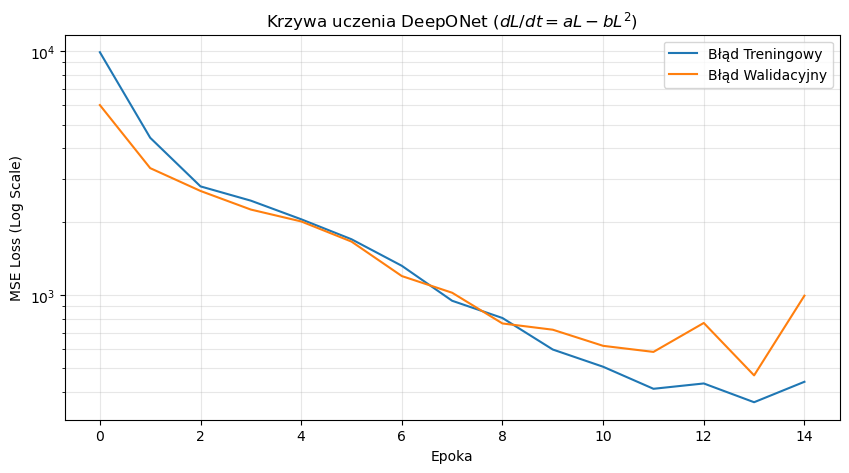

Zapisano: logistic_samples_deeponet.png


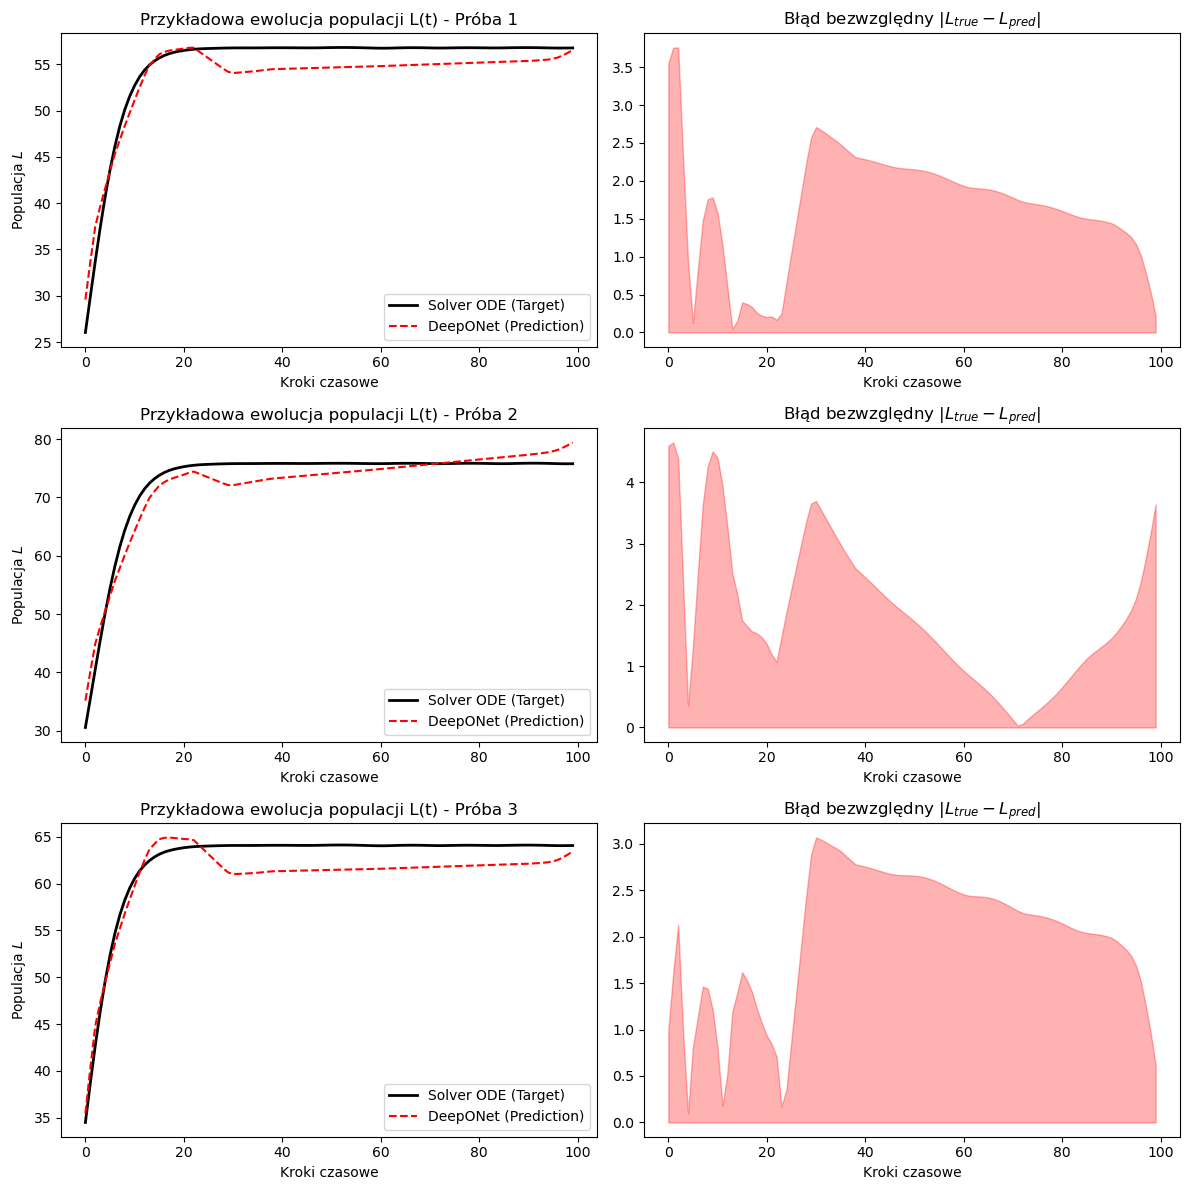

Plik logistic_stats_deeponet.png został zapisany pomyślnie.


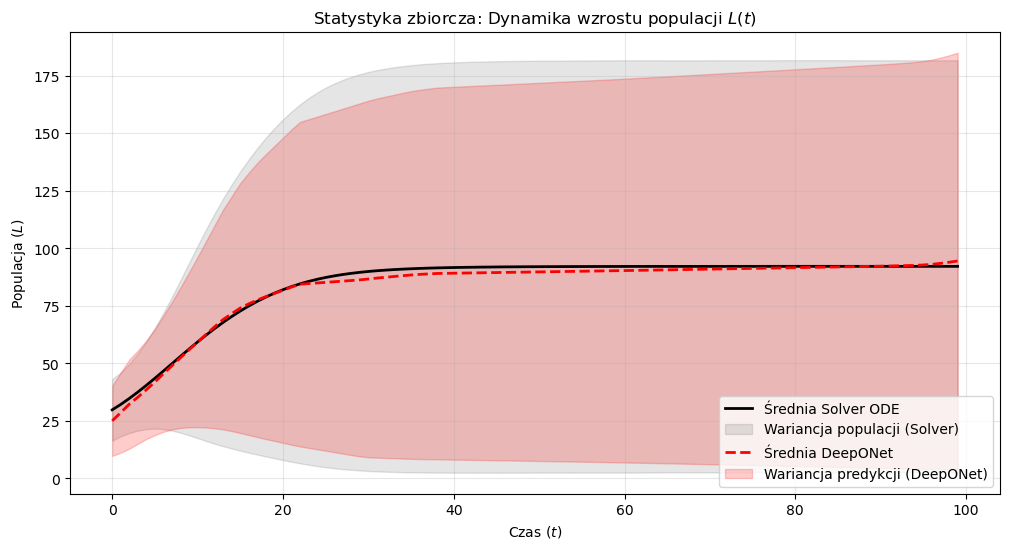

In [15]:
plot_history(history)
visualize_results(model, test_loader)
plot_mean_and_variance(model, test_loader)